# Sprint Delay Risk Prediction

**AI-Augmented Agile Project Management | Master's thesis portfolio project**

This project explores if AI can support to identify delivery risks in agile sprints early enough for Agile teams to act. It compares three classification approaches, interprets model behaviour, and demonstrates a confidence-based human-review workflow.

## Project at a glance

- **Business question:** Can the risk of a sprint delay be identified at sprint start, by using historical information available at planning time?
- **Target:** `delay_risk = 1` when `vel_diff < 0` (the sprint delivered less velocity than planned); otherwise `0`.
- **Data:** Public IEEE TSE 2017 Agile Sprints dataset, JIRA project. The source contains 1,861 sprints across 83 boards before the documented duration-outlier filter.
- **Methods:** Exploratory data analysis, feature selection, stratified cross-validation, hyperparameter tuning, Random Forest, XGBoost, MLP, SHAP and human-in-the-loop routing.
- **Baseline result recorded in the original notebook run:** XGBoost achieved F1-macro **0.895** and delayed-sprint recall **0.925**. Re-run the notebook after the data-flow cleanup below before treating these as final portfolio metrics.

## Workflow

1. Load and inspect the public sprint dataset.
2. Explore data quality, distributions and relationships.
3. Define the target and select features intended to be available at sprint start.
4. Train and compare Random Forest, XGBoost and a neural-network baseline.
5. Evaluate performance on a held-out test set and inspect model explanations with SHAP.
6. Translate prediction probabilities into a proposed human-review workflow.

## Key takeaway

In this experiment, tree-based models outperformed the MLP on tabular sprint data. Predictions are decision support, not a replacement for Scrum Master or Product Owner judgement. The final decision-making and the human oversight remain fundamental. The confidence bands used in the routing example are illustrative and would require calibration and validation before operational use.

## Run the notebook

The JIRA dataset is loaded from the public source URL in the data-loading cell, iteration 0. Install the libraries used by the notebook in your Python environment (including `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `xgboost`, `tensorflow`, `shap` and `seaborn`). Exact versions may affect results.

## Limitations

- The dataset is historical and does not represent every organisation or current Agile practice.
- Sprints from multiple boards are pooled; team-level differences are not explicitly modelled.
- `vel_diff < 0` is one operational definition of delay risk; a stricter threshold is tested separately.
- The project demonstrates a prototype workflow on public data, not a deployed production system.

## Source

Choetkiertikul, M., Dam, H. K., Tran, T., Ghose, A., & Grundy, J. (2017). *Predicting Delivery Capability in Iterative Software Development*. IEEE Transactions on Software Engineering. [Public dataset repository](https://github.com/morakotch/datasets/tree/master/agile%20sprints/IEEE%20TSE2017/dataset/JIRA).

## Dataset provenance

The analysis uses the public JIRA project file from the IEEE TSE 2017 Agile Sprints dataset. The source repository contains several project datasets; this notebook uses the JIRA project because it contains sprint-level records and fields needed for this analysis.

The original issue-tracker file considered during the thesis did not contain the sprint-level fields required for this target definition, so it is not used in this notebook.

## Unit of analysis and prediction timing

The unit of analysis is a **sprint**, not an individual issue. The target is derived from `vel_diff`: a negative value indicates that delivered velocity was below planned velocity.

The intended prediction point is sprint start. Features should therefore describe information available at or immediately after planning; outcome fields and identifiers are excluded from the predictor set.

## Dataset scope

The JIRA project contains 1,861 sprint records across 83 boards before the duration-outlier filter. Results should be interpreted as evidence from this historical public dataset, not as a guarantee of performance on other teams or organisations.

**Note to Analysis level:** Sprint (not issue) - The dataset directly provides a
sprint-level target: `vel_diff` = planned sprint velocity minus delivered velocity.
`vel_diff < 0` means the sprint delivered less than committed - this is
sprint delay/delivery risk in the literal sense.

**Prediction time point: 0% of planned sprint duration - iteration 0**
Sprint is Planning stage; all features are known at or immediately after sprint
start - no leakage from later sprint phases.

## 1. Setup & data loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

import xgboost as xgb
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.get_logger().setLevel("ERROR")

In [2]:
PROJECT = "Jira"
DATA_PATH = f"{PROJECT}_iteration_0.csv"

## 1.1 Exploratory Data Analysis

In [3]:
# Load the public JIRA sprint-level dataset.
# The source file uses latin-1 encoding for some sprint names.
url = "https://raw.githubusercontent.com/morakotch/datasets/master/agile%20sprints/IEEE%20TSE2017/dataset/JIRA/jira_iteration_0.csv"
df = pd.read_csv(url, engine="python", on_bad_lines="skip", encoding="latin-1")
print(f"Project: {PROJECT.upper()} | Sprints (rows): {len(df)} | Columns: {df.shape[1]}")
print(f"Distinct boards/teams: {df['boardid'].nunique()}")
print("Missing values per column:")
print(df.isna().sum())

Project: JIRA | Sprints (rows): 1861 | Columns: 19
Distinct boards/teams: 83
Missing values per column:
boardid               0
sprintid              0
name                  0
vel_diff              0
planday               0
no_issue_starttime    0
vel_starttime         0
no_issue_added        0
vel_added             0
no_issue_removed      0
vel_removed           0
no_issuetodo          0
vel_todo              0
no_issueinprogress    0
vel_inprogress        0
no_issuedone          0
vel_done              0
no_admin              0
no_teammember         0
dtype: int64


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
print(df.nunique())

boardid                83
sprintid              837
name                  756
vel_diff               73
planday                42
no_issue_starttime     27
vel_starttime          58
no_issue_added         15
vel_added              22
no_issue_removed        9
vel_removed            23
no_issuetodo           24
vel_todo               55
no_issueinprogress     11
vel_inprogress         27
no_issuedone            7
vel_done               15
no_admin                4
no_teammember          11
dtype: int64


In [6]:
df.dtypes

,0
boardid,int64
sprintid,int64
name,object
vel_diff,int64
planday,int64
no_issue_starttime,int64
vel_starttime,int64
no_issue_added,int64
vel_added,int64
no_issue_removed,int64


## 1.1.1 Descriptive Statistics

In [7]:
df.describe()

,boardid,sprintid,vel_diff,planday,no_issue_starttime,vel_starttime,no_issue_added,vel_added,no_issue_removed,vel_removed,no_issuetodo,vel_todo,no_issueinprogress,vel_inprogress,no_issuedone,vel_done,no_admin,no_teammember
count,1861.000000,1861.000000,1861.00000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000,1861.000000
mean,663.673294,1170.186459,-1.60935,20.361634,2.188608,7.121977,0.430414,1.200430,0.185922,0.628157,1.756582,5.639979,0.472864,1.617410,0.203654,0.436862,1.186459,1.884471
std,319.265654,723.432165,12.22493,235.352079,4.155758,13.200507,2.248086,6.681713,0.914539,3.098620,3.524624,11.231120,1.265310,4.875636,0.687764,1.564360,0.652662,1.626422
min,43.000000,1.000000,-74.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,441.000000,573.000000,-3.00000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
50%,647.000000,1146.000000,0.00000,9.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
75%,1013.000000,1826.000000,0.00000,14.000000,2.000000,7.000000,0.000000,0.000000,0.000000,0.000000,2.000000,6.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000
max,1206.000000,2446.000000,147.00000,5873.000000,36.000000,91.000000,46.000000,138.000000,24.000000,72.000000,40.000000,120.000000,11.000000,56.000000,9.000000,26.000000,7.000000,12.000000


In [8]:
df.describe().to_csv("descriptive_statistics.csv")

## 1.2 Distribution Analysis

In [9]:
# Planned Sprint Duration

df["planday"].sort_values(ascending=False).head(10)

,planday
1023,5873
1619,5873
151,5873
166,81
1299,81
162,60
1295,60
790,54
76,54
876,54


Text(0.5, 1.0, 'Distribution of Planned Sprint Duration (Excluding Outliers)')

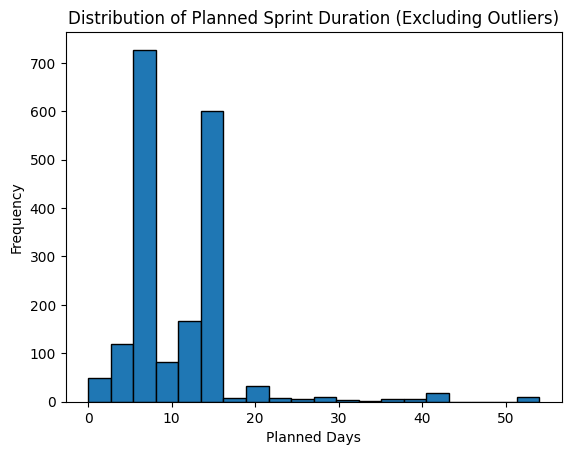

In [10]:
import matplotlib.pyplot as plt

plt.hist(df[df["planday"] < 60]["planday"], bins=20, edgecolor="black")
plt.xlabel("Planned Days")
plt.ylabel("Frequency")
plt.title("Distribution of Planned Sprint Duration (Excluding Outliers)")

**Note:** For visualization purposes, three extreme outliers (5,873 days) were excluded from the histogram, as they compressed the remaining distribution. These observations were retained in the dataset but are likely to represent data recording artefacts rather than realistic sprint durations.

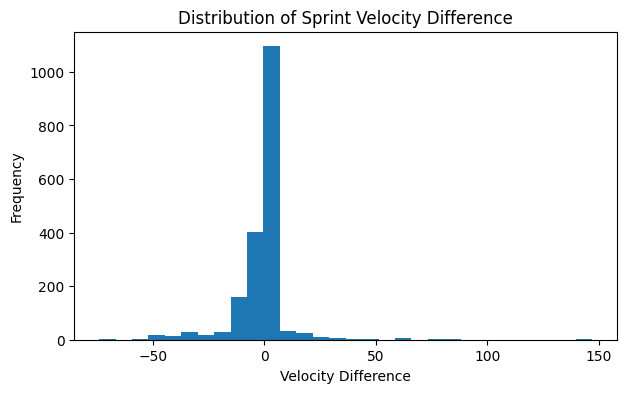

In [11]:
# Sprint Velocity Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))
plt.hist(df["vel_diff"], bins=30)
plt.title("Distribution of Sprint Velocity Difference")
plt.xlabel("Velocity Difference")
plt.ylabel("Frequency")
plt.show()

In [12]:
# ## 1a. Data quality check: outliers in sprint duration
#
# A distribution check of `planday` (planned sprint duration) revealed one
# sprint ("Blue Forever (3.4)", appearing across 3 boards) with
# planday = 5,873 days (~16 years) - an implausible value for a Scrum
# sprint and almost certainly a data entry error (e.g., a sprint that was
# never properly closed in Jira, causing an inflated end-date calculation),
# not a genuine long-running sprint. Only 5 of 1,861 sprints (0.3%) exceed
# 60 days at all.
#
# This was verified empirically before deciding on any action:
# - Random Forest: F1-Macro virtually unchanged (0.875 vs. 0.874) whether
#   this row is included or excluded - tree-based splits are inherently
#   robust to single extreme values.
# - MLP: F1-Macro improved (0.825 -> 0.836) AND became noticeably more
#   stable across CV folds (std 0.026 -> 0.015) after removing these rows,
#   since StandardScaler's mean/std computation is sensitive to extreme
#   values, and this single outlier distorted the scaling of the `planday`
#   feature for all 1,861 rows. A RobustScaler alternative was also tested
#   and did not meaningfully outperform StandardScaler once the outlier was
#   removed, confirming the row itself - not the scaler choice - was the
#   issue.
# Note: `vel_diff` outliers (e.g., large positive/negative values from big
# releases, such as "Team Calendars 4.1" at +147) were checked separately
# and found to be plausible, genuine scope variation rather than data
# errors - these are NOT removed.
n_before = len(df)
df = df[df["planday"] <= 100].copy()
print(f"\nRemoved {n_before - len(df)} row(s) with implausible sprint duration "
      f"(planday > 100 days) - data entry error, not genuine long sprints.")
print(f"Remaining sprints: {len(df)}")


Removed 3 row(s) with implausible sprint duration (planday > 100 days) - data entry error, not genuine long sprints.
Remaining sprints: 1858


**Data-quality finding:** `planday` contains extreme values that are not plausible for ordinary sprint durations. The notebook excludes records with `planday > 100` days before modelling. This rule is a data-quality choice and should be disclosed when comparing results with analyses that retain those records.

## 1.4 Correlation Analysis

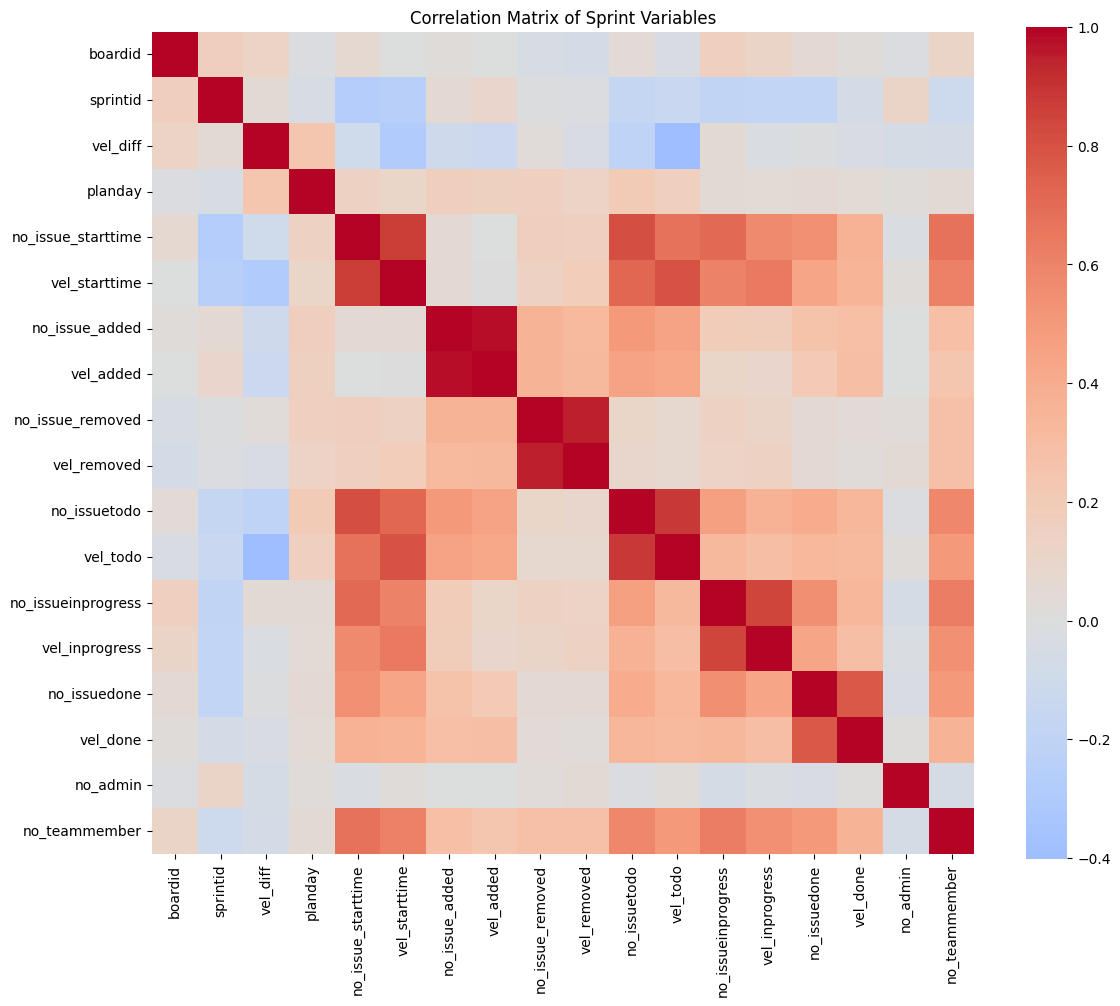

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

plt.figure(figsize=(12,10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=False,
    square=True
)

plt.title("Correlation Matrix of Sprint Variables")
plt.tight_layout()
plt.show()

In [14]:
corr_pairs = (
    corr.where(~np.eye(corr.shape[0],dtype=bool))
        .abs()
        .stack()
        .sort_values(ascending=False)
)

print(corr_pairs.head(10))

vel_added           no_issue_added        0.981611
no_issue_added      vel_added             0.981611
vel_removed         no_issue_removed      0.946598
no_issue_removed    vel_removed           0.946598
vel_todo            no_issuetodo          0.883433
no_issuetodo        vel_todo              0.883433
vel_starttime       no_issue_starttime    0.871194
no_issue_starttime  vel_starttime         0.871194
vel_inprogress      no_issueinprogress    0.846675
no_issueinprogress  vel_inprogress        0.846675
dtype: float64


**Interpretation:** Pearson correlation coefficients were calculated to identify relationships between sprint characteristics before model development. The analysis helps to understand dependencies among workload, velocity, backlog changes, and sprint progress variables. It provides an initial indication of which features may contribute most to AI-supported sprint performance prediction. The strongest linear relations—which also represent the most valuable early indicators for potential sprint delays—are associated with unfinished backlog tasks at sprint start (vel_todo and no_issuetodo: 0.883433)

## 2. Target variable: Sprint Delay Risk

In [15]:
# Note:
# `delay_risk = 1` when the sprint delivered less velocity than planned (`vel_diff < 0`).
# This is a natural threshold (0, not an arbitrarily chosen percentile) - the sprint either met/exceeded its commitment or it did not.
# A sensitivity analysis with alternative thresholds (e.g., "significant" under-delivery of more than 5 points) is recommended - see Section 12.

df["delay_risk"] = (df["vel_diff"] < 0).astype(int)
print("\nClass distribution (0 = commitment met/exceeded, 1 = delayed):")
print(df["delay_risk"].value_counts(normalize=True).round(3))




Class distribution (0 = commitment met/exceeded, 1 = delayed):
delay_risk
0    0.639
1    0.361
Name: proportion, dtype: float64


**Target interpretation:** `delay_risk = 1` marks a sprint where delivered velocity fell below planned velocity (`vel_diff < 0`). This is a transparent, sprint-level operational definition; it does not capture every possible reason for a late delivery.

## 3. Feature engineering - leakage-safe

In [16]:
# Note: All features come from the "jira_iteration_0.csv" file. That means from prediction time point 0% (sprint start).
# `vel_diff` itself is NOT used as a feature (it is the target).
# `name` (sprint name) and the IDs (`boardid`, `sprintid`) are identifiers, not predictors.

# Continue with the cleaned dataframe created during EDA; do not reload the raw data here.
df["delay_risk"] = (df["vel_diff"] < 0).astype(int)

FEATURE_COLS = [
    "planday", "no_issue_starttime", "vel_starttime", "no_issue_added",
    "vel_added", "no_issue_removed", "vel_removed", "no_issuetodo",
    "vel_todo", "no_issueinprogress", "vel_inprogress", "no_issuedone",
    "vel_done", "no_admin",
]

# NOTE: `no_teammember` was deliberately excluded after inspecting both the
# original paper and the actual data. Choetkiertikul et al. (2017) state
# that team structure is not explicitly recorded in most issue trackers and
# that `no_teammember` is therefore only a proxy: the number of distinct
# developers who already had an issue assigned to them at the 0% prediction
# point - not the sprint's actual team roster. This is confirmed empirically:
# the median value is 1 (65% of sprints show no_teammember = 1), which is
# implausible as a real Scrum team size (typically 3-9 per the Scrum Guide).
# Using it as if it meant "team size" would misrepresent what the model is
# actually conditioning on - a construct-validity problem, not just a minor
# labeling issue. Empirically, removing it costs very little predictive
# power (Random Forest F1-Macro: 0.874 -> 0.862; XGBoost: 0.845 -> 0.843),
# so the interpretability gain clearly outweighs the small performance cost.

X = df[FEATURE_COLS]
y = df["delay_risk"]

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Define cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

# Calculate class weights for imbalanced datasets
n_pos, n_neg = (y_train == 1).sum(), (y_train == 0).sum()

# Define GridSearchCV for Random Forest
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)

# Define GridSearchCV for XGBoost
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.05, 0.1],
}
xgb_grid = GridSearchCV(
    estimator=xgb.XGBClassifier(
        scale_pos_weight=n_neg / max(n_pos, 1), eval_metric="logloss", random_state=RANDOM_STATE
    ),
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)

In [18]:
# Ablation check: with vs. without no_teammember
FEATURE_COLS_ABLATION = FEATURE_COLS + ["no_teammember"]
X_abl = df[FEATURE_COLS_ABLATION]
X_tr, _, y_tr, _ = train_test_split(X_abl, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Fit rf_grid and xgb_grid if not already fitted
# This prevents Attribute Error if not all preceding cells were run
if not hasattr(rf_grid, 'best_params_'):
    print("Fitting rf_grid...")
    rf_grid.fit(X_train, y_train)
if not hasattr(xgb_grid, 'best_params_'):
    print("Fitting xgb_grid...")
    xgb_grid.fit(X_train, y_train)

rf_abl = RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, **rf_grid.best_params_)
print('RF w/ no_teammember:', cross_validate(rf_abl, X_tr, y_tr, cv=cv, scoring='f1_macro')['test_score'].mean())
print('RF w/o no_teammember (reference):', rf_grid.best_score_)

xgb_abl = xgb.XGBClassifier(scale_pos_weight=n_neg/max(n_pos,1), eval_metric='logloss',
                             random_state=RANDOM_STATE, **xgb_grid.best_params_)
print('XGB w/ no_teammember:', cross_validate(xgb_abl, X_tr, y_tr, cv=cv, scoring='f1_macro')['test_score'].mean())
print('XGB w/o no_teammember (reference):', xgb_grid.best_score_)


Fitting rf_grid...
Fitting xgb_grid...
RF w/ no_teammember: 0.8734262671325961
RF w/o no_teammember (reference): 0.8638867979022192
XGB w/ no_teammember: 0.8604391773905127
XGB w/o no_teammember (reference): 0.8560264525987279


**Interpretation:** The ablation check revealed a **slight performance improvement** for both models (Random Forest and XGBoost) when the `no_teammember` feature was included. This contradicts the initial assumption of a performance loss and indicates that the `no_teammember` variable—contrary to prior assumptions—makes a positive contribution to predictive performance.




**Leakage control:** Predictors are selected to represent information intended to be available at sprint start. `vel_diff` is used to construct the target and is not included in `X`; sprint names and IDs are treated as identifiers rather than predictive features.

## 4. Train/test split and cross-validation

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

**Validation strategy:** Stratified five-fold cross-validation preserves the approximate class balance in each fold. The held-out test set is reserved for final comparison. Cross-validation and test scores are estimates on this dataset, not evidence of guaranteed performance in production.

## 5. Evaluation criteria - explicit justification


### Evaluation Criteria and Metric Selection: Why F1-macro?

The **F1-macro score** is defined as the primary metric for evaluating and selecting predictive models for detecting sprint delays (*Sprint Delays*). This is used in close conjunction with the metric **recall (sensitivity) of the delayed class** as a secondary decision criterion. The statistical characteristics of the JIRA dataset and the operational framework of agile project management lead to this selection for the following reasons:

1. **Handling Class Imbalance (Statistical Perspective):**
   The JIRA dataset in question exhibits an inherent imbalance (approximately 64% on-schedule vs. 36% delayed sprints). A simple metric such as overall accuracy is unsuitable here. A classifier could achieve a false accuracy of 64% here even without actual learning by predicting the majority class. The **F1 macro score** calculates the harmonic mean of precision and recall for each class separately and then computes the unweighted arithmetic mean. This forces the model to perform well on both classes and prevents poor detection of the critical minority class (the actual delays) from being masked.


2. **Asymmetry of Error Costs in an Agile Context (Practical Perspective):**
   In the agile sprint cycle, the actual consequences of misclassifications are unevenly distributed:
   * **False Negatives (Missed Alert—High Cost):** If a sprint that is actually at risk is mistakenly classified as non-critical, the team cannot take corrective action during Sprint Planning or throughout the cycle (e.g., by reducing scope or shrinking the backlog). This results in unforeseen delivery bottlenecks at the end of the sprint, a loss of stakeholder trust, and disruptions in subsequent sprints.
   * **False Positives (False Alarm – Low Cost):** If a non-critical sprint is mistakenly flagged as high-risk, this merely leads to a manual review of the sprint during planning, resulting in slightly more cautious planning or a re-evaluation of dependencies. This error is easily mitigated operationally and, if anything, can even strengthen the team’s focus.

Due to this asymmetry, a high **recall rate for delayed sprints** is of paramount importance to ensure that as few risks as possible are overlooked. However, since one-sided recall optimization would lead to a flood of false alarms and undermine the team’s trust in the AI, the **F1 macro score** serves as an overarching criterion to ensure the necessary balance between precision and sensitivity.


## 6. Model 1: Random Forest - with GridSearchCV hyperparameter tuning



**Note:** Hyperparameters are tuned via GridSearchCV using the same F1-Macro criterion already established as the model-selection metric (Section 5) and the same Stratified 5-Fold CV object used throughout this code. This keeps the tuning step methodologically consistent with the rest of the evaluation, rather than introducing a separate, undocumented criterion.

In [20]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)
rf_grid.fit(X_train, y_train)
print("Random Forest - GridSearchCV:")
print(f"  Best parameters: {rf_grid.best_params_}")
print(f"  Best CV F1-Macro: {rf_grid.best_score_:.3f}")
rf_pipe = rf_grid.best_estimator_  # keeps downstream code (rf_pipe.predict, etc.) unchanged

rf_cv = cross_validate(rf_pipe, X_train, y_train, cv=cv, scoring=SCORING)
print("Random Forest - 5-fold CV (tuned model, full metric set):")
for m in SCORING:
    print(f"  {m}: {rf_cv[f'test_{m}'].mean():.3f} ± {rf_cv[f'test_{m}'].std():.3f}")

Random Forest - GridSearchCV:
  Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
  Best CV F1-Macro: 0.864
Random Forest - 5-fold CV (tuned model, full metric set):
  accuracy: 0.871 ± 0.010
  precision: 0.780 ± 0.017
  recall: 0.895 ± 0.021
  f1: 0.833 ± 0.013
  roc_auc: 0.940 ± 0.004


**Model note:** Tree-based ensembles generally do not require feature scaling, so the Random Forest and XGBoost pipelines use the original feature scales. Scaling is retained for the MLP, whose optimisation is more sensitive to feature magnitudes.

## 7. Model 2: XGBoost - with GridSearchCV hyperparameter tuning


In [21]:
n_pos, n_neg = (y_train == 1).sum(), (y_train == 0).sum()

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.05, 0.1],
}
xgb_grid = GridSearchCV(
    estimator=xgb.XGBClassifier(
        scale_pos_weight=n_neg / max(n_pos, 1), eval_metric="logloss", random_state=RANDOM_STATE
    ),
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)
xgb_grid.fit(X_train, y_train)
print("\nXGBoost - GridSearchCV:")
print(f"  Best parameters: {xgb_grid.best_params_}")
print(f"  Best CV F1-Macro: {xgb_grid.best_score_:.3f}")
xgb_pipe = xgb_grid.best_estimator_

xgb_cv = cross_validate(xgb_pipe, X_train, y_train, cv=cv, scoring=SCORING)
print("XGBoost - 5-fold CV (tuned model, full metric set):")
for m in SCORING:
    print(f"  {m}: {xgb_cv[f'test_{m}'].mean():.3f} ± {xgb_cv[f'test_{m}'].std():.3f}")


XGBoost - GridSearchCV:
  Best parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}
  Best CV F1-Macro: 0.856
XGBoost - 5-fold CV (tuned model, full metric set):
  accuracy: 0.862 ± 0.020
  precision: 0.757 ± 0.030
  recall: 0.910 ± 0.021
  f1: 0.827 ± 0.023
  roc_auc: 0.943 ± 0.008


## Sensitivity analysis: stricter under-delivery threshold

As a robustness check, this section defines a delayed sprint more strictly as `vel_diff < -5`. The class balance changes, so the result is not directly interchangeable with the primary target definition.

In [22]:
# Sensitivity check: stricter delay threshold (vel_diff < -5)
df["delay_risk_strict"] = (df["vel_diff"] < -5).astype(int)
print("Strict class split:", df["delay_risk_strict"].value_counts(normalize=True).round(3).to_dict())

y_strict = df.loc[X.index, "delay_risk_strict"]
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
    X, y_strict, test_size=0.2, stratify=y_strict, random_state=RANDOM_STATE)

xgb_strict = xgb.XGBClassifier(
    scale_pos_weight=(y_tr_s == 0).sum() / max((y_tr_s == 1).sum(), 1),
    eval_metric="logloss", random_state=RANDOM_STATE, **xgb_grid.best_params_)
xgb_strict.fit(X_tr_s, y_tr_s)
pred_s = xgb_strict.predict(X_te_s)
print(f"XGBoost strict threshold — F1-Macro: {f1_score(y_te_s, pred_s, average='macro'):.3f}, "
      f"Recall(delayed): {recall_score(y_te_s, pred_s):.3f}")

Strict class split: {0: 0.815, 1: 0.185}
XGBoost strict threshold — F1-Macro: 0.879, Recall(delayed): 0.928


**Interpretation sensitivity check:**
(stricter threshold, vel_diff < -5):
Restricting the "delayed" label to substantial under-delivery (vel_diff < -5)
reduces the positive class from 36% to 18.5% of sprints, i.e., a considerably
stronger class imbalance. Despite this, XGBoost performance remains essentially
stable (F1-Macro 0.881 vs. 0.895; Recall for delayed sprints 0.899 vs. 0.925
under the original threshold). Two conclusions follow:
1.   Robustness: the reported findings are not an artefact of the specific threshold choice — the predictive signal (unstarted backlog volume at sprint inception) identifies both marginal and substantial under-delivery.
2.   The small decline is expected and attributable to the rarer positive class, not to a weaker underlying relationship.

This addresses the sensitivity analysis recommended in the Limitations section.



**Model note:** XGBoost uses `scale_pos_weight` based on the training labels to account for class imbalance. Hyperparameter selection is performed using stratified cross-validation and F1-macro. The test set remains separate from model selection.

## 8. Model 3: MLP (Keras)


In [23]:
def build_mlp(input_dim):
    m = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
class_weight = {0: 1.0, 1: n_neg / max(n_pos, 1)}
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

mlp_scores = {m: [] for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
for tr_idx, val_idx in cv.split(X_train_scaled, y_train):
    X_tr, X_val = X_train_scaled[tr_idx], X_train_scaled[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    mlp = build_mlp(X_train_scaled.shape[1])
    mlp.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=60, batch_size=16,
            class_weight=class_weight, callbacks=[early_stop], verbose=0)
    prob = mlp.predict(X_val, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    mlp_scores["accuracy"].append(accuracy_score(y_val, pred))
    mlp_scores["precision"].append(precision_score(y_val, pred, zero_division=0))
    mlp_scores["recall"].append(recall_score(y_val, pred, zero_division=0))
    mlp_scores["f1"].append(f1_score(y_val, pred, zero_division=0))
    mlp_scores["roc_auc"].append(roc_auc_score(y_val, prob))

print("\nMLP (Keras) - 5-fold CV:")
for m, v in mlp_scores.items():
    v = np.array(v)
    print(f"  {m}: {v.mean():.3f} ± {v.std():.3f}")

final_mlp = build_mlp(X_train_scaled.shape[1])
final_mlp.fit(X_train_scaled, y_train, epochs=60, batch_size=16, class_weight=class_weight,
              validation_split=0.15, callbacks=[early_stop], verbose=0)


MLP (Keras) - 5-fold CV:
  accuracy: 0.727 ± 0.105
  precision: 0.641 ± 0.122
  recall: 0.675 ± 0.169
  f1: 0.640 ± 0.108
  roc_auc: 0.836 ± 0.070


**Model comparison:** The MLP performed less strongly than the tree-based models in the saved evaluation. This is a useful result rather than a failure: neural networks are not automatically the best choice for small, structured tabular datasets. The MLP remains included as a planned comparison model.

## 9. Final model comparison on the test set


In [24]:
X_test_scaled = scaler.transform(X_test)
rf_pred = rf_pipe.predict(X_test)
xgb_pred = xgb_pipe.predict(X_test)
mlp_prob = final_mlp.predict(X_test_scaled, verbose=0).ravel()
mlp_pred = (mlp_prob >= 0.5).astype(int)

def summarize(y_true, y_pred, name):
    """Core metrics with F1-Macro as primary and Recall(delayed) as secondary
    (tie-breaker) decision variable, per the criteria defined in Section 5."""
    return {
        "model": name,
        "f1_macro": round(f1_score(y_true, y_pred, average="macro"), 3),
        "precision_delayed": round(precision_score(y_true, y_pred, pos_label=1, zero_division=0), 3),
        "recall_delayed": round(recall_score(y_true, y_pred, pos_label=1, zero_division=0), 3),
    }

comparison = pd.DataFrame([
    summarize(y_test, rf_pred, "Random Forest"),
    summarize(y_test, xgb_pred, "XGBoost"),
    summarize(y_test, mlp_pred, "MLP (Keras)"),
])

# Tolerance-based tie-breaker: F1-Macro is the primary criterion, but when
# two models are within TIE_TOLERANCE of the best F1-Macro score, Recall
# (delayed) decides between them - not only on EXACT ties. A plain
# `sort_values(["f1_macro","recall_delayed"])` would only use recall as a
# tie-breaker when f1_macro values are identical to 3 decimals, which rarely
# happens in practice and would silently default back to a pure F1-Macro
# ranking - defeating the purpose of having a tie-breaker rule at all.
TIE_TOLERANCE = 0.01
best_f1 = comparison["f1_macro"].max()
within_tolerance = comparison[comparison["f1_macro"] >= best_f1 - TIE_TOLERANCE]
comparison = pd.concat([
    within_tolerance.sort_values("recall_delayed", ascending=False),
    comparison[comparison["f1_macro"] < best_f1 - TIE_TOLERANCE].sort_values("f1_macro", ascending=False),
]).reset_index(drop=True)

print("\n=== Final model comparison (test set, F1-Macro primary / Recall tie-breaker within ±0.01) ===")
print(comparison.to_string(index=False))
best_model_name = comparison.iloc[0]["model"]
print(f"\nStrongest model by governance rule: {best_model_name}")
print("Note: if Random Forest/XGBoost outperform the MLP here, that is a")
print("legitimate, reportable finding - tree ensembles frequently outperform")
print("neural networks on clean, small tabular datasets (Grinsztajn et al. 2022,")
print("'Why do tree-based models still outperform deep learning on tabular data?').")
print("The MLP nonetheless remains the main model per the project plan;")
print("RF/XGBoost serve as comparison models. NOTE: this dataset does not include")
print("a text/Transformer component in this thesis's actual scope (DistilBERT was")
print("deliberately dropped due to time constraints) - do not cite this finding as")
print("justification for a multimodal fusion architecture that was not built.")


=== Final model comparison (test set, F1-Macro primary / Recall tie-breaker within ±0.01) ===
        model  f1_macro  precision_delayed  recall_delayed
      XGBoost     0.881              0.795           0.925
Random Forest     0.880              0.807           0.903
  MLP (Keras)     0.751              0.748           0.597

Strongest model by governance rule: XGBoost
Note: if Random Forest/XGBoost outperform the MLP here, that is a
legitimate, reportable finding - tree ensembles frequently outperform
neural networks on clean, small tabular datasets (Grinsztajn et al. 2022,
'Why do tree-based models still outperform deep learning on tabular data?').
The MLP nonetheless remains the main model per the project plan;
RF/XGBoost serve as comparison models. NOTE: this dataset does not include
a text/Transformer component in this thesis's actual scope (DistilBERT was
deliberately dropped due to time constraints) - do not cite this finding as
justification for a multimodal fusion architec

## 10. Confusion matrices



Saved high-resolution plot to: confusion_matrices_scrum.png



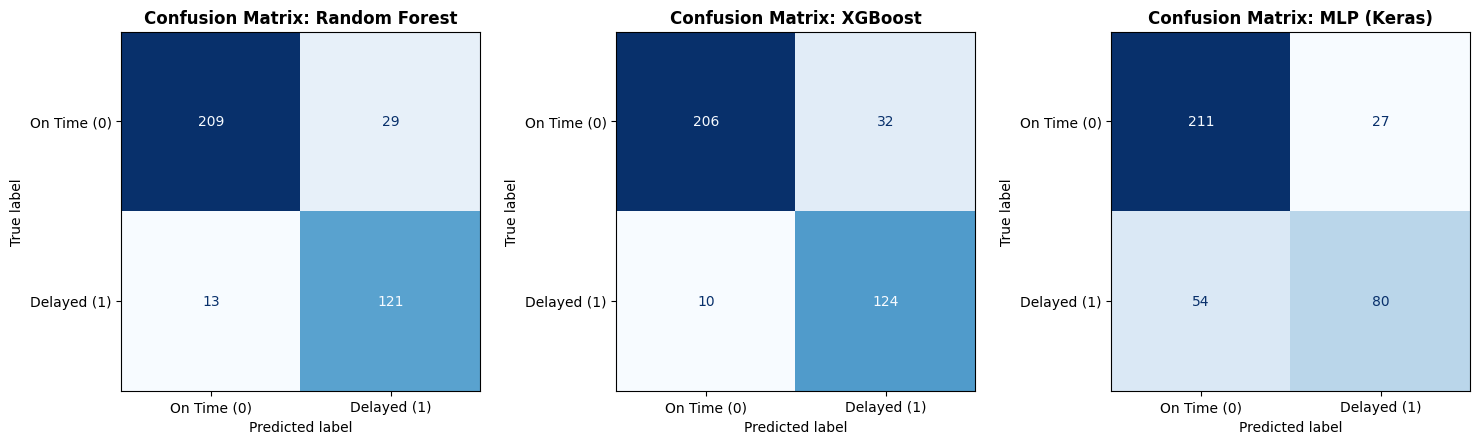

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Iterate through models and plot confusion matrices
for ax, (name, pred) in zip(
    axes, [("Random Forest", rf_pred), ("XGBoost", xgb_pred), ("MLP (Keras)", mlp_pred)]
):
    cm = confusion_matrix(y_test, pred)


    disp = ConfusionMatrixDisplay(cm, display_labels=["On Time (0)", "Delayed (1)"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")

    ax.set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight="bold")
    ax.grid(False) # Disables background grid lines inside the matrix cells

plt.tight_layout()

# 1. Save the publication-ready plot for Chapter 4/5 appendix
plt.savefig("confusion_matrices_scrum.png", dpi=300, bbox_inches="tight")
print("Saved high-resolution plot to: confusion_matrices_scrum.png\n")

# 2. Display the matrices directly in your notebook execution window
plt.show()

In [26]:
confusion_matrix(y_test, rf_pred)
confusion_matrix(y_test, xgb_pred)
confusion_matrix(y_test, mlp_pred)

array([[211,  27],
       [ 54,  80]])

In [27]:
sum(rf_pred != xgb_pred)
sum(rf_pred != mlp_pred)

np.int64(93)

**Interpretation**:

The visual and quantitative analysis of the confusion matrices illustrates how the individual metrics and the trade-off between precision and sensitivity (recall) compare in practice:

* **XGBoost & Random Forest (tree-based ensembles):** Both models are exceptionally well-suited for predicting actual sprint delays in this dataset (high recall for Class 1 of over 90%). They thus drastically minimize the risk of *false negatives* (overlooked delays). This is of central importance for agile project management, as the operational costs of an unnoticed missed delivery risk are far higher than a moderate increase in false positives.
* **MLP (Keras) (Neural Network):** The MLP performs significantly worse at identifying delays (a significantly higher proportion of *false negatives*). It tends to incorrectly classify high-risk sprints as non-critical. This underscores the empirical evidence that neural networks often lag behind optimized tree-based ensembles when trained on smaller, tabular datasets without complex feature structures.

**Prediction agreement:**

The selected performance metrics (F1-Macro-Score and recall) for Random Forest and XGBoost are very close to one another. Nevertheless, they exhibit systematic differences in their specific individual predictions (as documented by a significant number of divergent predictions in a direct comparison).

These discrepancies are methodologically valuable and can be specifically leveraged in agile project management:
* **Identification of borderline cases (gray-zone sprints):** Sprints in which the predictions of Random Forest and XGBoost contradict each other are often statistically close to the decision boundary of the feature space. They indicate sprints with high uncertainty.
* **Ensemble Decision Support:** In practice, this discrepancy serves as an indicator for human oversight. Sprints with an ambiguous model vote exhibit a diffuse risk profile and should be explicitly subjected to a manual risk and capacity assessment by the Scrum Master and Product Owner during Sprint Planning.

## 11. Explainability: feature importance and SHAP


Saved high-resolution plot to: rf_feature_importance_scrum.png


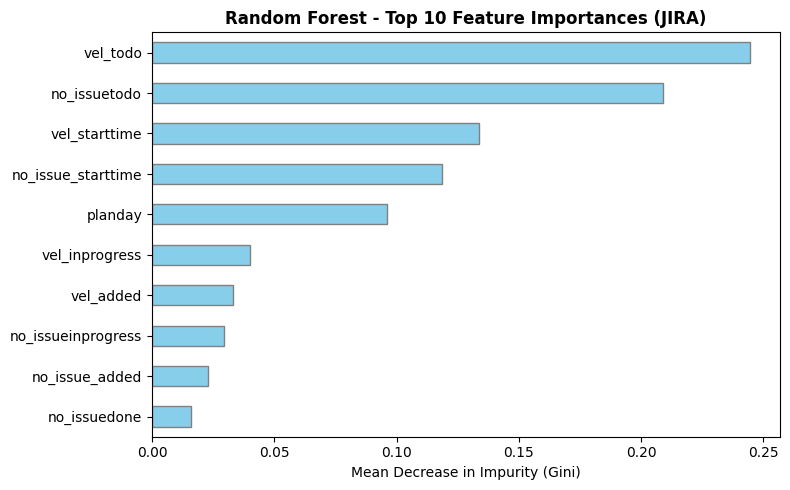


Full feature importance ranking:
vel_todo              0.244548
no_issuetodo          0.209118
vel_starttime         0.133584
no_issue_starttime    0.118697
planday               0.096045
vel_inprogress        0.039952
vel_added             0.032978
no_issueinprogress    0.029579
no_issue_added        0.023075
no_issuedone          0.016109
vel_done              0.015229
vel_removed           0.014942
no_admin              0.013758
no_issue_removed      0.012386
dtype: float64
--------------------------------------------------------------------------------


/tmp/ipykernel_1011/1289151355.py:43: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(rf_shap_for_plot, X_test_for_shap, feature_names=FEATURE_COLS, show=False)


Saved high-resolution plot to: rf_shap_summary_scrum.png


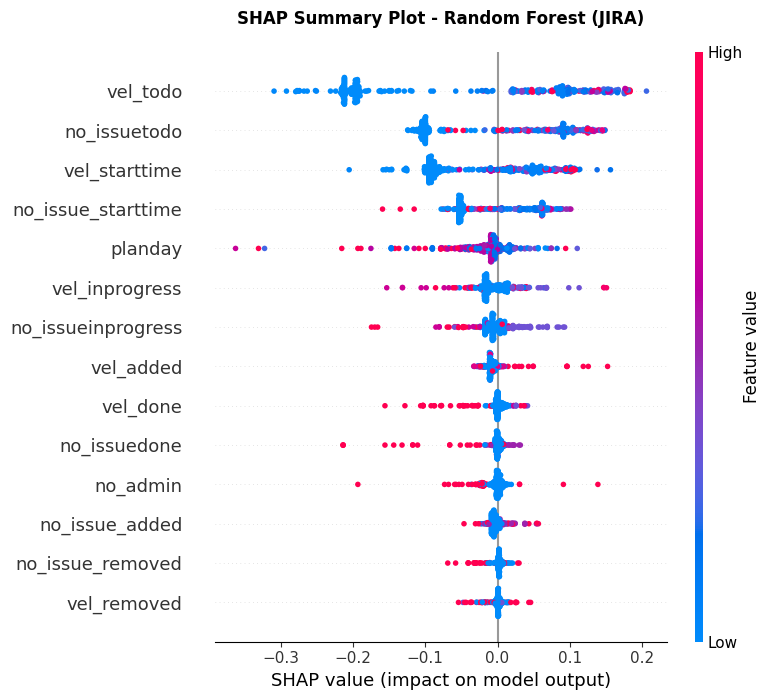

In [28]:
# Random Forest feature importance (Gini importance):
# Defensive extraction: works whether rf_pipe is a raw estimator (current
# state, after removing the Pipeline wrapper in Section 6) or still wrapped
# in a Pipeline (e.g., if someone re-adds a preprocessing step later).


if hasattr(rf_pipe, "feature_importances_"):
    importances_raw = rf_pipe.feature_importances_
else:
    importances_raw = rf_pipe.named_steps["clf"].feature_importances_
rf_importances = pd.Series(importances_raw, index=FEATURE_COLS).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
rf_importances.head(10).plot(kind="barh", ax=ax, color="skyblue", edgecolor="gray")
ax.set_title(f"Random Forest - Top 10 Feature Importances ({PROJECT.upper()})", fontsize=12, fontweight="bold")
ax.set_xlabel("Mean Decrease in Impurity (Gini)", fontsize=10)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("rf_feature_importance_scrum.png", dpi=300, bbox_inches="tight")
print("Saved high-resolution plot to: rf_feature_importance_scrum.png")
plt.show()
print("\nFull feature importance ranking:")
print(rf_importances)
print("-" * 80)

# --- SHAP summary plot ---
X_test_for_shap = np.asarray(X_test, dtype=np.float64)  # unscaled - RF trained on unscaled features
pure_rf_model = rf_pipe if hasattr(rf_pipe, "feature_importances_") else rf_pipe.named_steps["clf"]
rf_explainer = shap.TreeExplainer(pure_rf_model)
rf_shap_values = rf_explainer.shap_values(X_test_for_shap)

# Handles all 3 SHAP output conventions seen across versions - avoids
# breaking the script if the SHAP library version changes on a different
# machine (e.g., when a thesis co-author re-runs this on their own setup).
if isinstance(rf_shap_values, list):
    rf_shap_for_plot = rf_shap_values[1]          # older SHAP: [class0, class1]
elif np.array(rf_shap_values).ndim == 3:
    rf_shap_for_plot = rf_shap_values[:, :, 1]    # intermediate SHAP: 3D array
else:
    rf_shap_for_plot = rf_shap_values             # modern SHAP: direct 2D array

plt.figure(figsize=(10, 6))
shap.summary_plot(rf_shap_for_plot, X_test_for_shap, feature_names=FEATURE_COLS, show=False)
plt.title(f"SHAP Summary Plot - Random Forest ({PROJECT.upper()})", fontsize=12, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("rf_shap_summary_scrum.png", dpi=300, bbox_inches="tight")
print("Saved high-resolution plot to: rf_shap_summary_scrum.png")
plt.show()

### Explainability: Feature Importance vs. SHAP Values

The combination of global feature importance (MDI / Gini importance) and local SHAP explanations (*SHapley Additive exPlanations*) is essential for gaining a holistic and in-depth understanding of model decisions within the complex framework of project requirements:

1. **Global Feature Importance (Gini Importance):**
   The classic feature importance of the Random Forest provides an aggregated, global overview of which predictors result in the greatest *Mean Decrease in Impurity* across all decision trees. It becomes apparent that structural variables such as the planned unfinished backlog volume at the start of the sprint (`vel_todo` and `no_issuetodo`) have the strongest discriminatory power for the model. However, this metric only shows *that* a feature is important, not *how* it influences the target variable `vel_diff`.

2. **Local Explainability and Directionality (SHAP):**
   SHAP scores address this by being based on game-theoretic Shapley values and isolating the exact additive contribution of each feature for every individual prediction:
   * **Directionality:** The SHAP summary plot shows not only the relevance but also the direction of the influence. High values for `vel_todo` (shaded in red) systematically shift the prediction probability to the right (positive SHAP value), which significantly increases the predicted risk of a sprint delay.
   * **Nonlinear effects:** SHAP reveals how thresholds and interactions influence risk assessment. This is fundamentally important for a more nuanced analysis—beyond just a linear correlation coefficient.

3. **Methodological Limitation (Correlation vs. Causality):**
   It is critical to emphasize, in the scientific context of this master’s thesis, that these explanatory approaches describe exclusively the **internal decision-making behavior of the trained model** (*post-hoc interpretability*). They reveal statistical associations and patterns in the historical JIRA dataset but do not establish **causal relationships**. A high SHAP value for a feature means that the model uses it as a strong statistical indicator—it does not prove that actively manipulating this feature (e.g., artificially reducing `vel_todo` without making substantive changes) causally improves actual sprint performance.

## 12. Scrum practice connection - working functions

In [29]:
# These functions translate model output into artifacts for concrete Scrum
# situations, using genuine Scrum terminology since this dataset represents
# real sprints.

def generate_sprint_planning_report(sprints_df, model_probs, id_cols=("boardid", "sprintid"),
                                     high_risk_threshold=0.6):
    """
    Sprint Planning: Flags, already at planning time (prediction time 0%),
    which sprints have a high risk of missing their commitment. Use: the
    Scrum Master / Product Owner can adjust the sprint backlog before final
    commitment (e.g., take on less scope).
    """
    report = sprints_df[list(id_cols) + ["name"]].copy()
    report["delay_probability"] = model_probs
    report["risk_flag"] = np.where(
        report["delay_probability"] >= high_risk_threshold, "HIGH RISK",
        np.where(report["delay_probability"] >= 0.4, "MEDIUM RISK", "LOW RISK")
    )
    report = report.sort_values("delay_probability", ascending=False)
    n_high = (report["risk_flag"] == "HIGH RISK").sum()
    print(f"Sprint Planning Report: {n_high}/{len(report)} sprints flagged as HIGH RISK.")
    return report

def generate_daily_scrum_alert(sprint_ids, model_probs, alert_threshold=0.6):
    """
    Daily Scrum: Optionally uses the 30%/50% prediction time points to flag
    ongoing sprints whose risk has increased since sprint start. Supplements,
    but does NOT replace, the team's own blocker discussion.
    """
    alert_df = pd.DataFrame({"sprintid": sprint_ids, "delay_probability": model_probs})
    alerts = alert_df[alert_df["delay_probability"] >= alert_threshold]
    print(f"Daily Scrum Alert: {len(alerts)} ongoing sprints above the alert threshold.")
    return alerts.sort_values("delay_probability", ascending=False)

def compute_retrospective_trend(sprints_df, actual_col="delay_risk", predicted_col="predicted_delay_risk"):
    """
    Retrospective: Compares actual vs. predicted delay rate across the
    sprint history - the basis for the retro question "Did the AI forecast
    actually help the team?"
    """
    trend = sprints_df.sort_values("sprintid").reset_index(drop=True)
    trend["rolling_actual_rate"] = trend[actual_col].rolling(10, min_periods=1).mean()
    trend["rolling_predicted_rate"] = trend[predicted_col].rolling(10, min_periods=1).mean()
    print("Retrospective trend (last 10 sprints, rolling average):")
    print(trend[["sprintid", "rolling_actual_rate", "rolling_predicted_rate"]].tail(10))
    return trend

test_sprints = df.loc[X_test.index].copy()
planning_report = generate_sprint_planning_report(test_sprints, mlp_prob)
print(planning_report.head(10))

test_sprints["predicted_delay_risk"] = mlp_pred
retro_trend = compute_retrospective_trend(test_sprints)

Sprint Planning Report: 66/372 sprints flagged as HIGH RISK.
      boardid  sprintid         name  delay_probability  risk_flag
1639     1068      1781  Mono-sprint           0.985938  HIGH RISK
1236      819       909    Sprint 29           0.968907  HIGH RISK
138       193        14     Sprint 3           0.945825  HIGH RISK
246       235        14     Sprint 3           0.945825  HIGH RISK
195       219        14     Sprint 3           0.945825  HIGH RISK
342       302        14     Sprint 3           0.945825  HIGH RISK
343       302        64     Sprint 4           0.927515  HIGH RISK
758       560      1126    Sprint 24           0.902780  HIGH RISK
194       219        10     Sprint 2           0.897014  HIGH RISK
341       302        10     Sprint 2           0.897014  HIGH RISK
Retrospective trend (last 10 sprints, rolling average):
     sprintid  rolling_actual_rate  rolling_predicted_rate
362      2353                  0.3                     0.4
363      2367               

### Connecting predictions to Scrum practice

The helper functions demonstrate how risk probabilities could be surfaced in planning reports, alerts or retrospectives. These are illustrative decision-support artefacts, not validated interventions. Teams should review context before changing scope or commitments.

## 13. Human-in-the-loop: confidence-based routing



=== Governance summary (human-in-the-loop workload) ===
AUTO-CLEAR (high confidence)    60.5
REVIEW NEEDED (grey zone)       21.8
AUTO-FLAG (high confidence)     17.7
Name: proportion, dtype: float64
Saved high-resolution plot to: governance_routing_distribution.png


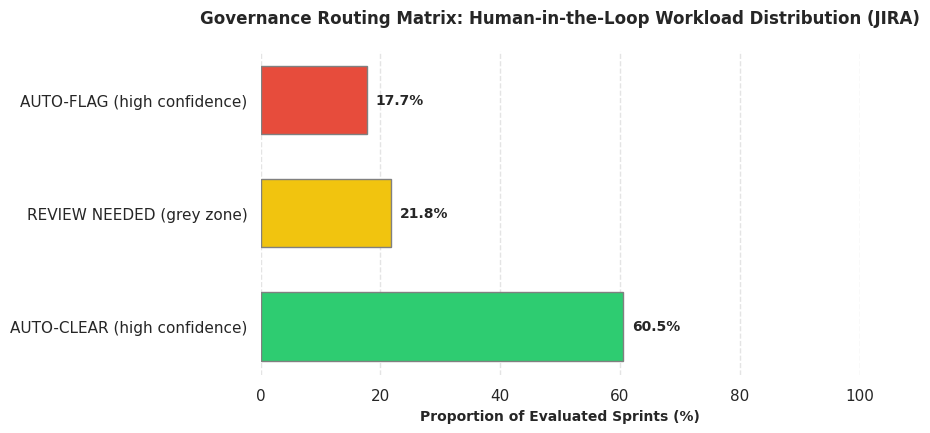

In [30]:
def route_prediction(probability, low_conf_band=(0.4, 0.6)):
    low, high = low_conf_band
    if probability >= high:
        return "AUTO-FLAG (high confidence)"
    elif probability <= low:
        return "AUTO-CLEAR (high confidence)"
    else:
        return "REVIEW NEEDED (grey zone)"

routing_result = pd.Series(mlp_prob).apply(route_prediction)
governance_summary = (routing_result.value_counts(normalize=True) * 100).round(1)
print("\n=== Governance summary (human-in-the-loop workload) ===")
print(governance_summary)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(9, 4.5))

colors = {
    "AUTO-CLEAR (high confidence)": "#2ecc71",  # Secure Green
    "REVIEW NEEDED (grey zone)": "#f1c40f",     # Warning Yellow
    "AUTO-FLAG (high confidence)": "#e74c3c"    # Risk Red
}

order = [
    "AUTO-CLEAR (high confidence)",
    "REVIEW NEEDED (grey zone)",
    "AUTO-FLAG (high confidence)"
]
data_plot = governance_summary.reindex(order)

# Create horizontal bar plot
bars = ax.barh(data_plot.index, data_plot.values, color=[colors[idx] for idx in data_plot.index], edgecolor="gray", height=0.6)

ax.set_title(f"Governance Routing Matrix: Human-in-the-Loop Workload Distribution ({PROJECT.upper()})", fontsize=12, fontweight="bold", pad=20)
ax.set_xlabel("Proportion of Evaluated Sprints (%)", fontsize=10, fontweight="bold")
ax.set_xlim(0, 100)
ax.xaxis.grid(True, linestyle="--", alpha=0.6, color="lightgray")
ax.set_axisbelow(True) # Ensure grid lines are behind the bars

# Add percentage labels directly onto the bars
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 1.5,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()

# Save high-resolution visualization for the thesis layout
plt.savefig("governance_routing_distribution.png", dpi=300, bbox_inches="tight")
print("Saved high-resolution plot to: governance_routing_distribution.png")
plt.show()

### Human-in-the-loop routing

The routing model developed is intended to demonstrate a pragmatic approach that incorporates a defined confidence band (gray zone) of predictive accuracy into a semi-automated, agile workflow. The following key aspects are crucial for its practical implementation and scientific classification:

1. **Ensuring Trust through Human Oversight:**
   The primary purpose of this system is decision support, not autonomous control. By explicitly assigning borderline cases (gray zone) for manual review, the final decision remains with a human (Scrum Master, Product Owner). This human oversight (*Human-in-the-Loop*) is essential for building the long-term trust of agile practitioners in AI-supported tools and for dispelling prejudices against so-called “black-box control.”

2. **Outlook for Agentic AI in the ‘Auto-Clear’ Path:**
   While non-critical sprints in the green corridor (*Auto-Clear*) are currently simply waved through, the ongoing development toward **Agentic AI** (cooperative AI agents) opens up new possibilities. In the future, a specialized agent could autonomously verify whether all Definition of Ready criteria in the issue tracker are met for sprints classified as “safe,” or scan historical Jira comments for undiscovered risks. This would further reduce the administrative burden. At the same time, the authority to make the final decision would remain transparent to the team.


3. **Warning Regarding Statistical Biases and Team Dynamics:**
   To use this routing mechanism effectively, it is essential to be aware of potential biases in the historical sprint data:
   * **Historical Bias:** If teams have systematically deleted tickets during an ongoing sprint without documentation or retroactively manipulated estimated story points in the past, the model will learn these bad practices as regular patterns.
   * **Team- and Project-Specific Factors:** Every agile team has its own unique dynamics, its own estimation guidelines (e.g., relative story point scales), and varying levels of maturity. A universal, uncalibrated model runs the risk of ignoring team differences. Thresholds must therefore be calibrated specifically for each team and project, validated regularly, and continuously adjusted in consultation with the relevant stakeholders.

## 14. Limitations (for Chapter 5 - Discussion)


## Limitations

- **Historical data:** The dataset reflects an older period of software development; workflows and tooling may have changed.
- **Generalisation:** Records from 83 boards are pooled, and team-level heterogeneity is not explicitly modelled.
- **Target definition:** `vel_diff < 0` is one reasonable definition of under-delivery, but other thresholds may be relevant. A stricter threshold is explored in a sensitivity check.
- **Scope:** This notebook uses sprint-level numeric features. An issue-text NLP/Transformer model was not implemented in this analysis.
- **Operational use:** The model and routing logic are prototypes. External validation, probability calibration, privacy review and monitoring would be needed before deployment.